# Rural fires in four Portuguese municipalities

## Scope and research objectives

This observational study examines records of rural fires in **Alijó, Mirandela, Alcácer do Sal and Odemira**. It compares **2014–2016** with **2018–2020**, excluding **2017** from the comparisons. The analysis is based on selected records from the SGIF dataset, not on repeated random sampling.

The report investigates six related questions:

1. Did the **mean monthly number of recorded fires** change between the two periods?
2. Does the **mean time from alert to first intervention** differ among municipalities?
3. Is the **recorded alert source** associated with municipality?
4. Did the proportion of incidents with alert source **`Populares`** change between periods?
5. Do **burned-area distributions** differ among municipalities?
6. Is the **recorded cause-group classification** associated with municipality?

Statistical tests use a **5% significance level**. We report effects and uncertainty where available; statistically significant associations are **not** interpreted as proof of causation.

**Reading guide:** Each analysis is followed immediately by a discussion of its observed results. These interpretations are based on the outputs of the supplied `report(1).ipynb`. If the dataset, filters or code change, rerun the cells and update the numerical statements.

In [1]:
from pathlib import Path
import unicodedata
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

ALPHA = 0.05
MUNICIPALITIES = ['Alijó', 'Mirandela', 'Alcácer do Sal', 'Odemira']
YEARS = [2014, 2015, 2016, 2018, 2019, 2020]
PRE, POST = '2014-2016', '2018-2020'
DATA_PATH_CANDIDATES = [
    Path('13-Registos-Incendios-SGIF-2011-2020') / 'Registos_Incendios_SGIF_2011_2020.xlsx',
    Path('Registos_Incendios_SGIF_2011_2020.xlsx'),
]
DATA_PATH = next((p for p in DATA_PATH_CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Place the SGIF Excel next to this notebook, or edit DATA_PATH_CANDIDATES.')
print('Using dataset:', DATA_PATH.resolve())

Using dataset: /mnt/data/Registos_Incendios_SGIF_2011_2020.xlsx


## 1. Inspect the source dataset

The original workbook contains incident-level records. We first inspect its structure, then select the variables needed for the analyses. The unit of observation in the source file is a **recorded fire incident**, except where counts are subsequently aggregated by municipality and month.

In [2]:
fires = pd.read_excel(DATA_PATH, sheet_name='SGIF_2011_2020')
print(f'Full dataset: {fires.shape[0]:,} rows and {fires.shape[1]} columns')
fires.head()


Full dataset: 177,129 rows and 41 columns


,Codigo_SGIF,Codigo_ANEPC,Ano,Mes,Dia,Hora,AreaPov_ha,AreaMato_ha,AreaAgric_ha,AreaTotal_ha,ClasseArea,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,IncSup24horas,DTCCFR,Distrito,Concelho,Freguesia,Local,RNAP,RNMPF,X_Militar,Y_Militar,Latitude,Longitude,X_ETRS89,Y_ETRS89,DSR,FWI,ISI,DC,DMC,FFMC,BUI,CodCausa,TipoCausa,GrupoCausa,DescricaoCausa,FonteAlerta
0,DM2111,368,2011,1,1,17,0.0,0.010,0.00000,0.01000,]0 a 1 ha[,2011-01-01 17:53:00,2011-01-01 18:05:00,2011-01-01 18:37:00,0.733333,0,131127,Porto,Penafiel,Portela,LUGAR DE JUGUEIROS (Lugar da Bouça),NaN,NaN,188599,459305,41.102778,-8.268611,-11401.109382,159301.890769,2.820904e-04,0.075682,0.291930,4.092373,0.653638,54.525424,0.934234,145.0,Negligente,Uso do fogo - Fogueiras,Fogueiras - Outras,Populares
1,BL4112,1236,2011,1,9,22,0.0,0.000,0.00200,0.00200,]0 a 1 ha[,2011-01-09 22:17:00,2011-01-09 22:29:00,2011-01-09 23:56:00,1.650000,0,101514,Leiria,Pombal,Vila Cã,CASAIS VILA Cã,NaN,NaN,161044,323077,39.875000,-8.588333,-38954.323380,23076.994096,1.074211e-06,0.003252,0.013831,1.835452,0.367371,32.001278,0.489703,610.0,Desconhecida,Indeterminadas,Indeterminadas - Prova material,Populares
2,DM3111,820,2011,1,15,17,0.0,0.000,0.00001,0.00001,]0 a 1 ha[,2011-01-15 17:51:00,2011-01-15 18:05:00,2011-01-16 05:34:00,11.716667,0,161014,Viana do Castelo,Vila Nova de Cerveira,Vila Meã,JUNTO AO BRASEIRÃO (Vila Meã),NaN,NaN,154334,556828,41.979444,-8.683889,-45666.852138,256820.365617,4.795222e-03,0.375100,1.171990,9.658571,1.573768,74.889775,2.236498,124.0,Negligente,Queimas amontoados de sobrantes florestais ou ...,Queima de amontoados - Borralheiras,Populares
3,BL2111,1977,2011,1,18,22,0.0,0.001,0.00000,0.00100,]0 a 1 ha[,2011-01-18 22:50:00,2011-01-18 22:53:00,2011-01-18 23:25:00,0.583333,0,61112,Coimbra,Oliveira do Hospital,Oliveira do Hospital,Oliveira do Hospital,NaN,NaN,222661,375604,40.348611,-7.866111,22661.336515,75603.740547,2.414996e-04,0.069323,0.248910,12.477199,0.762519,51.102608,1.322920,124.0,Negligente,Queimas amontoados de sobrantes florestais ou ...,Queima de amontoados - Borralheiras,Populares
4,DM2113,7930,2011,1,19,17,0.0,0.005,0.00000,0.00500,]0 a 1 ha[,2011-01-19 17:53:00,2011-01-19 17:58:00,2011-01-19 18:40:00,0.783333,0,131701,Porto,Vila Nova de Gaia,Arcozelo,TRAV. DOS CAÇADORES (Travessa dos Caçadores),NaN,NaN,156602,454024,41.054167,-8.649167,-43397.335208,154020.398590,4.658263e-07,0.002028,0.008092,3.968661,0.508191,32.290416,0.769912,NaN,NaN,NaN,NaN,Populares


## 2. Prepare and filter the dataset

Municipality names are standardised to account for differences in accents and capitalisation. The data are restricted to the four selected municipalities and the six years of interest. Response time is calculated as the interval, in minutes, between the alert and the first intervention; missing or negative response intervals are excluded from analyses of that variable only.

In [3]:
USE_COLS = ['Codigo_SGIF','Concelho','Ano','Mes','AreaTotal_ha','FWI',
            'DataHoraAlerta','DataHora_PrimeiraIntervencao','FonteAlerta','GrupoCausa']
fires = pd.read_excel(DATA_PATH, sheet_name='SGIF_2011_2020', usecols=USE_COLS)
print('Records in source:', len(fires))

def normalize_text(value):
    if pd.isna(value):
        return ''
    txt = unicodedata.normalize('NFKD', str(value))
    return ''.join(ch for ch in txt if not unicodedata.combining(ch)).casefold().strip()

mun_map = {normalize_text(m): m for m in MUNICIPALITIES}
fires['Municipio'] = fires['Concelho'].map(lambda x: mun_map.get(normalize_text(x)))
df = fires.loc[fires['Municipio'].notna() & fires['Ano'].isin(YEARS)].copy()
df['Periodo'] = np.where(df['Ano'] <= 2016, PRE, POST)
df['Mes'] = pd.to_numeric(df['Mes'], errors='coerce')
for column in ['DataHoraAlerta','DataHora_PrimeiraIntervencao']:
    df[column] = pd.to_datetime(df[column], errors='coerce')
df['TempoPrimeiraIntervencao_min'] = (
    (df['DataHora_PrimeiraIntervencao'] - df['DataHoraAlerta']).dt.total_seconds() / 60
)
invalid_response = df['TempoPrimeiraIntervencao_min'].isna() | (df['TempoPrimeiraIntervencao_min'] < 0)
df.loc[invalid_response, 'TempoPrimeiraIntervencao_min'] = np.nan

# Standardise text to compare accents, casing, and accidental whitespace.
df['FonteAlerta_key'] = df['FonteAlerta'].map(normalize_text)
df.loc[df['FonteAlerta_key'].eq(''), 'FonteAlerta_key'] = np.nan
PUBLIC_KEY = normalize_text('Populares')

print('Selected records:', len(df))
print('Invalid/missing response:', int(invalid_response.sum()))
print('Missing alert source:', int(df['FonteAlerta_key'].isna().sum()))
print('Missing cause group:', int(df['GrupoCausa'].isna().sum()))
print('Duplicate SGIF IDs:', int(df['Codigo_SGIF'].duplicated().sum()))
print('Month outside 1..12:', int((~df['Mes'].between(1, 12)).sum()))
print('Largest response times (check data quality):')
display(df[['Municipio','Ano','DataHoraAlerta','DataHora_PrimeiraIntervencao',
            'TempoPrimeiraIntervencao_min']].nlargest(10,'TempoPrimeiraIntervencao_min'))
display(df.groupby(['Municipio','Periodo']).size().unstack(fill_value=0))

Records in source: 177129


Selected records: 884
Invalid/missing response: 2
Missing alert source: 0
Missing cause group: 37
Duplicate SGIF IDs: 0
Month outside 1..12: 0
Largest response times (check data quality):


,Municipio,Ano,DataHoraAlerta,DataHora_PrimeiraIntervencao,TempoPrimeiraIntervencao_min
83494,Alcácer do Sal,2014,2014-07-28 20:03:00,2014-07-28 22:23:00,140.0
156615,Mirandela,2018,2018-11-19 18:14:00,2018-11-19 20:20:00,126.0
163703,Odemira,2019,2019-08-19 11:28:00,2019-08-19 13:04:00,96.0
176720,Odemira,2020,2020-10-16 16:30:00,2020-10-16 17:55:00,85.0
157347,Odemira,2019,2019-02-24 18:54:00,2019-02-24 20:18:00,84.0
148152,Mirandela,2018,2018-05-13 20:08:00,2018-05-13 21:30:00,82.0
157117,Odemira,2019,2019-02-09 19:32:00,2019-02-09 20:54:00,82.0
93828,Odemira,2015,2015-06-04 05:21:00,2015-06-04 06:32:00,71.0
177010,Odemira,2020,2020-11-04 03:10:00,2020-11-04 04:21:00,71.0
147328,Alijó,2018,2018-05-03 14:12:00,2018-05-03 15:20:00,68.0


Periodo,2014-2016,2018-2020
Municipio,,
Alcácer do Sal,85,70
Alijó,116,71
Mirandela,186,115
Odemira,128,113


### Interpretation — data quality and sample composition

The source workbook contains **177,129 records**, of which **884** meet the municipality and year filters. There are **515 incidents in 2014–2016** and **369 in 2018–2020**. By municipality, the retained dataset contains **301 records from Mirandela, 241 from Odemira, 187 from Alijó and 155 from Alcácer do Sal**.

The quality checks report **two missing or invalid first-intervention times** and **37 missing cause-group classifications**. No missing alert-source values, duplicated SGIF identifiers or months outside the 1–12 range were detected within the filtered data. The two invalid response-time observations are excluded from response-time inference, while the 37 unknown cause-group cases are excluded only from the cause analysis.

**Why this matters:** Different tests use slightly different numbers of valid observations, and the results refer **only to these selected municipalities and periods**. Filtering the dataset by place and year is not equivalent to randomly sampling all Portuguese fires. The largest response times shown above should be reviewed as plausible observations rather than discarded merely for being unusual.

## 3. Descriptive statistics and graphical exploration

Descriptive summaries and figures are examined before formal inference. The mean describes the arithmetic average, the median describes the middle observation, and the spread helps identify heterogeneous or asymmetric data. The monthly series includes **months with zero recorded incidents**, so it does not inflate the monthly mean by omitting zero-count months.

Occurrences  ...  Valid_responses
Municipio      Periodo                 ...                 
Alcácer do Sal 2014-2016           85  ...               85
               2018-2020           70  ...               70
Alijó          2014-2016          116  ...              116
               2018-2020           71  ...               70
Mirandela      2014-2016          186  ...              186
               2018-2020          115  ...              115
Odemira        2014-2016          128  ...              128
               2018-2020          113  ...              112

[8 rows x 7 columns]

Monthly observations by period:


,Monthly observations
Periodo,
2014-2016,144
2018-2020,144


Zero-months: 90


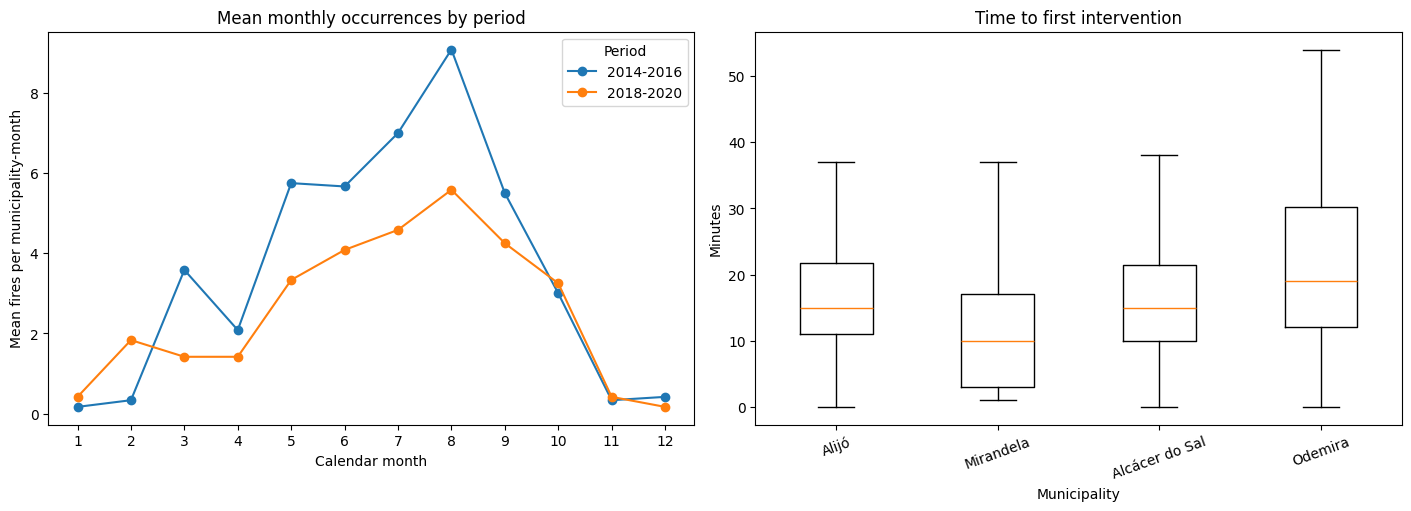

In [4]:

# --------------------------------------------------
# DESCRIPTIVE STATISTICS
# --------------------------------------------------

summary = df.groupby(
    ['Municipio', 'Periodo']
).agg(
    Occurrences=(
        'Codigo_SGIF', 'size'
    ),
    Mean_burned_area_ha=(
        'AreaTotal_ha', 'mean'
    ),
    Median_burned_area_ha=(
        'AreaTotal_ha', 'median'
    ),
    Mean_FWI=(
        'FWI', 'mean'
    ),
    Mean_response_min=(
        'TempoPrimeiraIntervencao_min', 'mean'
    ),
    Median_response_min=(
        'TempoPrimeiraIntervencao_min', 'median'
    ),
    Valid_responses=(
        'TempoPrimeiraIntervencao_min', 'count'
    )
)

display(summary.round(2))


# --------------------------------------------------
# COMPLETE MONTHLY COUNTS
# --------------------------------------------------

# NEW: include months with zero recorded fires

calendar = pd.MultiIndex.from_product(
    [
        MUNICIPALITIES,
        YEARS,
        range(1, 13)
    ],
    names=['Municipio', 'Ano', 'Mes']
)

monthly_counts = (
    df.groupby(['Municipio', 'Ano', 'Mes'])
    .size()
    .reindex(calendar, fill_value=0)
    .rename('Ocorrencias')
    .reset_index()
)

monthly_counts['Periodo'] = np.where(
    monthly_counts['Ano'] <= 2016,
    PRE,
    POST
)

print('Monthly observations by period:')

display(
    monthly_counts.groupby('Periodo')
    .size()
    .rename('Monthly observations')
    .to_frame()
)

print('Zero-months:', int(
    (monthly_counts['Ocorrencias'] == 0).sum()
))


# --------------------------------------------------
# ORIGINAL TWO-PANEL VISUALIZATION
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 5),
    constrained_layout=True
)

# Chart 1 — monthly occurrences
monthly_pattern = (
    monthly_counts.groupby(
        ['Periodo', 'Mes']
    )['Ocorrencias']
    .mean()
    .unstack('Periodo')
    .reindex(columns=[PRE, POST])
)

monthly_pattern.plot(
    ax=axes[0],
    marker='o'
)

axes[0].set(
    title='Mean monthly occurrences by period',
    xlabel='Calendar month',
    ylabel='Mean fires per municipality-month'
)

axes[0].set_xticks(range(1, 13))
axes[0].legend(title='Period')


# Chart 2 — response times by municipality
response_plot_data = [
    df.loc[
        df['Municipio'].eq(m),
        'TempoPrimeiraIntervencao_min'
    ].dropna().to_numpy()
    for m in MUNICIPALITIES
]

axes[1].boxplot(
    response_plot_data,
    tick_labels=MUNICIPALITIES,
    showfliers=False
)

axes[1].set(
    title='Time to first intervention',
    xlabel='Municipality',
    ylabel='Minutes'
)

axes[1].tick_params(
    axis='x',
    labelrotation=20
)

plt.show()


### Interpretation — descriptive results and plots

The number of recorded fires falls from **515 to 369** between the two three-year periods, a decrease of **146 incidents (approximately 28.3%)** in the selected municipalities. Counts decline in **all four municipalities**: Alijó (**116 to 71**), Mirandela (**186 to 115**), Alcácer do Sal (**85 to 70**) and Odemira (**128 to 113**). This is a descriptive change and does not yet establish a statistically significant difference or its cause.

Across the eight municipality-period combinations, the **median burned areas are small** (approximately **0.05–0.20 ha**), whereas some arithmetic means are considerably larger. For instance, Alijó has a mean of **31.40 ha** in 2018–2020 but a median of **0.20 ha**. This large gap suggests a strongly right-skewed burned-area distribution, in which a few large fires can influence means substantially. The mean must therefore not be taken as a typical incident size without considering the median and dispersion.

The response-time boxplot indicates differences in the centres and spreads of the distributions. The option to hide plotted outliers improves readability but **does not remove those observations from the statistical tests**. The recorded fire-weather index (`FWI`) is presented descriptively; no inferential relationship between FWI and the outcomes is established in this report.

The completed municipality-month calendar contains **288 observations**: **144 per period** (4 municipalities × 3 years × 12 months). Of these, **90 municipality-months have zero recorded fires**. Including them is important for a fair comparison of monthly fire frequency.

## 4. Statistical methods and assumptions

All tests are observational comparisons. Their null hypotheses represent **no population-level difference or association**, while alternatives represent the relevant difference or association.

| Research question | Method | Main null hypothesis | Important conditions |
|---|---|---|---|
| Monthly fire counts by period | Welch independent-samples t-test | Equal mean monthly counts in the two periods | Approximately suitable sampling distribution of means; independent municipality-month measurements; unequal variances allowed |
| First-intervention time by municipality | Welch one-way ANOVA | Equal population mean response times for all four municipalities | Independent incidents and sufficiently reliable mean-based inference; unequal variances allowed |
| Municipality vs. alert source | Chi-square test of independence | Municipality and recorded alert-source category are independent | Independent records; sufficiently large expected cell counts |
| `Populares` share by period | Two-proportion Z-test | Equal proportions in both periods | Independent incident indicators; adequate successes and failures |
| Burned area by municipality | Kruskal–Wallis test | Same rank distributions across the four municipalities | Independent observations; ordinal/continuous outcome; interpretation as a location difference needs comparable shapes |
| Municipality vs. recorded cause group | Chi-square test of independence | Municipality and cause category are independent | Independent records; sufficiently large expected cell counts |

**Statistical significance is not the same as practical importance.** In addition to p-values, we inspect confidence intervals, observed effect sizes, and descriptive distributions. Temporal dependence, seasonal patterns and the selected-municipality scope limit inference; these issues are discussed further below.

## 5. Research question 1 — Did monthly fire frequency change?

We compare the mean number of recorded incidents per **municipality-month** in 2014–2016 and 2018–2020 with a two-sided Welch t-test. The reported difference is defined as **post minus pre**, so a negative estimate indicates fewer incidents in the later period. A 95% confidence interval quantifies uncertainty about this difference.

In [5]:

# --------------------------------------------------
# RQ1 — WELCH T-TEST FOR MONTHLY FIRE COUNTS
# --------------------------------------------------

# Separate monthly counts into the two periods
monthly_groups = [
    monthly_counts.loc[
        monthly_counts['Periodo'] == period,
        'Ocorrencias'
    ].to_numpy()
    for period in [PRE, POST]
]

pre_monthly, post_monthly = monthly_groups

# Check sample sizes
print('PRE sample size:', len(pre_monthly))
print('POST sample size:', len(post_monthly))

# Descriptive statistics
print('PRE mean:', pre_monthly.mean())
print('POST mean:', post_monthly.mean())

# Welch two-sample t-test
# Order: POST - PRE
occurrence_ttest = stats.ttest_ind(
    post_monthly,
    pre_monthly,
    equal_var=False
)

print('Welch t-test for monthly counts:')
print(occurrence_ttest)

# --------------------------------------------------
# 95% CONFIDENCE INTERVAL FOR MEAN DIFFERENCE
# --------------------------------------------------

mean_difference = (
    post_monthly.mean() - pre_monthly.mean()
)

v_post = (
    post_monthly.var(ddof=1)
    / len(post_monthly)
)

v_pre = (
    pre_monthly.var(ddof=1)
    / len(pre_monthly)
)

standard_error = np.sqrt(v_post + v_pre)

# Welch-Satterthwaite degrees of freedom
welch_df = (
    (v_post + v_pre)**2
    /
    (
        v_post**2 / (len(post_monthly) - 1)
        +
        v_pre**2 / (len(pre_monthly) - 1)
    )
)

# Critical t value
t_critical = stats.t.ppf(
    1 - ALPHA / 2,
    welch_df
)

# Confidence interval
ci_lower = mean_difference - t_critical * standard_error
ci_upper = mean_difference + t_critical * standard_error

print('Mean difference (POST - PRE):', mean_difference)
print('Welch degrees of freedom:', welch_df)
print('95% confidence interval:', (ci_lower, ci_upper))
print('p-value:', occurrence_ttest.pvalue)
print('Reject H0 at 5%:', occurrence_ttest.pvalue < ALPHA)


PRE sample size: 144
POST sample size: 144
PRE mean: 3.576388888888889
POST mean: 2.5625
Welch t-test for monthly counts:
TtestResult(statistic=np.float64(-2.318884606652698), pvalue=np.float64(0.021193442998756473), df=np.float64(254.63034901986546))
Mean difference (POST - PRE): -1.0138888888888888
Welch degrees of freedom: 254.63034901986558
95% confidence interval: (np.float64(-1.8749390339858403), np.float64(-0.15283874379193751))
p-value: 0.021193442998756473
Reject H0 at 5%: True


### Results and interpretation — monthly fire frequency

The estimated mean decreases from **3.576 fires per municipality-month** in 2014–2016 to **2.563** in 2018–2020. The estimated difference (post − pre) is **−1.014 fires per municipality-month**. The **95% confidence interval is [−1.875, −0.153]**, which excludes zero. The Welch test gives **t = −2.319**, approximately **254.63 degrees of freedom**, and **p = 0.0212**.

Because **p < 0.05**, we reject the null hypothesis of equal period means **under the test's assumptions**. There is statistical evidence that the mean recorded monthly fire frequency differed between these periods in the four selected municipalities; the estimate indicates a **lower frequency in 2018–2020**.

**Interpretive caution:** The standardised difference, calculated later in the notebook, is only approximately **Cohen's d = −0.27**, indicating a relatively small effect on that scale. Moreover, observations from neighbouring months and the same municipality may not be independent because of seasonality and persistence in fire conditions. The Welch p-value and confidence interval should therefore be interpreted as **model-based results**, not as definitive evidence of a causal change after 2017.

## 6. Research question 2 — Do first-intervention times differ across municipalities?

Time to first intervention is measured in **minutes after the recorded alert**. We compare the **four municipality-specific means** using Welch ANOVA, which does not require equal group variances. Its overall result indicates whether at least one mean differs, but not which pairs differ.

In [6]:

# --------------------------------------------------
# RQ2 — WELCH ANOVA FOR RESPONSE TIMES
# --------------------------------------------------

# Create one response-time sample per municipality
response_groups = [
    df.loc[
        df['Municipio'] == municipality,
        'TempoPrimeiraIntervencao_min'
    ].dropna().to_numpy()
    for municipality in MUNICIPALITIES
]

# Descriptive statistics
print('Response time summary by municipality:')

display(
    df.groupby('Municipio')[
        'TempoPrimeiraIntervencao_min'
    ]
    .agg(['count', 'mean', 'median', 'std'])
    .reindex(MUNICIPALITIES)
    .round(2)
)

# --------------------------------------------------
# WELCH ANOVA FUNCTION
# --------------------------------------------------

def welch_anova(groups):

    groups = [
        np.asarray(group, dtype=float)
        for group in groups
    ]

    # Remove missing and non-finite values
    groups = [
        group[np.isfinite(group)]
        for group in groups
    ]

    k = len(groups)

    sample_sizes = np.array(
        [len(group) for group in groups],
        dtype=float
    )

    if k < 3 or (sample_sizes < 2).any():
        raise ValueError(
            'At least 3 groups with 2 observations each are required.'
        )

    means = np.array([
        group.mean()
        for group in groups
    ])

    variances = np.array([
        group.var(ddof=1)
        for group in groups
    ])

    if (
        not np.isfinite(variances).all()
        or (variances <= 0).any()
    ):
        raise ValueError(
            'All groups must have positive finite variances.'
        )

    # Welch weights
    weights = sample_sizes / variances

    weighted_mean = (
        np.sum(weights * means)
        / np.sum(weights)
    )

    # Welch correction term
    correction_term = np.sum(
        (1 / (sample_sizes - 1))
        * (1 - weights / np.sum(weights)) ** 2
    )

    numerator = (
        np.sum(
            weights * (means - weighted_mean) ** 2
        )
        / (k - 1)
    )

    correction = (
        1
        +
        (2 * (k - 2) / (k**2 - 1))
        * correction_term
    )

    statistic = numerator / correction

    # Degrees of freedom
    numerator_df = k - 1

    denominator_df = (
        (k**2 - 1)
        / (3 * correction_term)
    )

    # p-value
    p_value = stats.f.sf(
        statistic,
        numerator_df,
        denominator_df
    )

    return (
        statistic,
        p_value,
        numerator_df,
        denominator_df
    )

# --------------------------------------------------
# EXECUTE WELCH ANOVA
# --------------------------------------------------

response_anova = welch_anova(response_groups)

print('Welch ANOVA for response time:')
print('F statistic:', response_anova[0])
print('p-value:', response_anova[1])
print('df1:', response_anova[2])
print('df2:', response_anova[3])
print('Reject H0 at 5%:', response_anova[1] < ALPHA)


Response time summary by municipality:


,count,mean,median,std
Municipio,,,,
Alijó,186,17.77,15.0,11.88
Mirandela,301,12.70,10.0,13.21
Alcácer do Sal,155,18.30,15.0,13.96
Odemira,240,23.38,19.0,16.37


Welch ANOVA for response time:
F statistic: 23.39760538430099
p-value: 4.585914375758065e-14
df1: 3
df2: 438.3353785254638
Reject H0 at 5%: True


### Results and interpretation — Welch ANOVA for response time

The mean response times are **12.70 min in Mirandela** (n = 301), **17.77 min in Alijó** (n = 186), **18.30 min in Alcácer do Sal** (n = 155), and **23.38 min in Odemira** (n = 240). These are mean times **from alert to first intervention**, not total extinguishing times. Two records with missing or invalid response time are excluded.

Welch ANOVA gives **F = 23.40**, **df = (3, 438.34)**, and **p ≈ 4.59 × 10⁻¹⁴**. We therefore **reject the hypothesis of equal population mean response times** at the 5% level. The evidence suggests that **at least one municipality differs**.

Descriptively, **Mirandela has the shortest mean response time** and **Odemira the longest** among the four selected municipalities. However, this overall test does not establish that *every* pair is significantly different. Pairwise comparisons with multiplicity adjustment are reported below. Differences cannot be assigned to municipal efficiency without accounting for factors such as access, incident location, weather, reporting practices and available resources.

### Additional checks — effect size and unequal variances

The next cell calculates an effect-size summary for the monthly-count comparison and Levene tests for the variation in monthly counts and response times. These checks help interpret the suitability of Welch methods.

In [7]:
periods = sorted(df['Periodo'].dropna().unique())
pre_period, post_period = periods[0], periods[1]

pre_monthly = monthly_counts.loc[monthly_counts['Periodo'] == pre_period, 'Ocorrencias']
post_monthly = monthly_counts.loc[monthly_counts['Periodo'] == post_period, 'Ocorrencias']
mean_difference = post_monthly.mean() - pre_monthly.mean()
pooled_sd = np.sqrt(((len(pre_monthly) - 1) * pre_monthly.var(ddof=1) + (len(post_monthly) - 1) * post_monthly.var(ddof=1)) / (len(pre_monthly) + len(post_monthly) - 2))
cohens_d = mean_difference / pooled_sd
print('Period order:', pre_period, 'to', post_period)
print('Mean monthly occurrence difference (post - pre):', round(mean_difference, 2))
print("Cohen's d:", round(cohens_d, 2))
print('Levene test, monthly counts:', stats.levene(pre_monthly, post_monthly))
print('Levene test, response times:', stats.levene(*response_groups))


Period order: 2014-2016 to 2018-2020
Mean monthly occurrence difference (post - pre): -1.01
Cohen's d: -0.27
Levene test, monthly counts: LeveneResult(statistic=np.float64(6.734322549258087), pvalue=np.float64(0.009945365825622967))
Levene test, response times: LeveneResult(statistic=np.float64(5.130179113533401), pvalue=np.float64(0.0016029766181266919))


### Interpretation — dispersion and the choice of Welch tests

For monthly counts, **Cohen's d = −0.27**, a modest observed standardised difference between the two periods. The Levene test indicates evidence against equal variances for monthly counts (**p = 0.00995**) and response times (**p = 0.00160**). This supports the choice of **Welch versions** of the t-test and ANOVA, which accommodate unequal group variances.

Levene's test does **not** verify independence or the adequacy of normal approximations. The temporal structure of monthly counts and the right tails in response times must still be considered. A small p-value in Levene's test is evidence of unequal variability, not evidence that the group means differ.

## 7. Which municipalities differ in first-intervention time?

After the significant overall Welch ANOVA, we use **pairwise Welch t-tests** and the **Holm correction** to control the family-wise Type I error rate over the six comparisons. The sign of a difference corresponds to the mean of municipality 1 minus the mean of municipality 2.

In [8]:

# --------------------------------------------------
# POST-HOC RESPONSE-TIME COMPARISONS
# --------------------------------------------------

response_by_municipality = {
    name: group[
        'TempoPrimeiraIntervencao_min'
    ].dropna().to_numpy()
    for name, group in df.groupby(
        'Municipio',
        sort=True
    )
}

# --------------------------------------------------
# PAIRWISE WELCH T-TESTS
# --------------------------------------------------

pairwise = []

for first, second in combinations(
    response_by_municipality,
    2
):

    group1 = response_by_municipality[first]
    group2 = response_by_municipality[second]

    result = stats.ttest_ind(
        group1,
        group2,
        equal_var=False
    )

    pairwise.append({
        'Municipio 1': first,
        'Municipio 2': second,
        'Mean difference (1-2)': (
            group1.mean() - group2.mean()
        ),
        't_statistic': result.statistic,
        'p_raw': result.pvalue
    })

# --------------------------------------------------
# SORT BY P-VALUE
# --------------------------------------------------

pairwise = (
    pd.DataFrame(pairwise)
    .sort_values('p_raw')
    .reset_index(drop=True)
)

# --------------------------------------------------
# HOLM CORRECTION
# --------------------------------------------------

m = len(pairwise)

holm_values = (
    pairwise['p_raw'].to_numpy()
    * (m - np.arange(m))
)

pairwise['p_holm'] = np.minimum(
    1,
    np.maximum.accumulate(holm_values)
)

# --------------------------------------------------
# SIGNIFICANCE
# --------------------------------------------------

pairwise['Significativo_0.05'] = (
    pairwise['p_holm'] < ALPHA
)

print('Pairwise Welch t-tests with Holm correction:')

display(pairwise.round(5))

print(
    'Significant comparisons:',
    int(pairwise['Significativo_0.05'].sum())
)


Pairwise Welch t-tests with Holm correction:


,Municipio 1,Municipio 2,Mean difference (1-2),t_statistic,p_raw,p_holm,Significativo_0.05
0,Mirandela,Odemira,-10.67817,-8.19737,0.00000,0.00000,True
1,Alijó,Mirandela,5.06782,4.37926,0.00002,0.00008,True
2,Alcácer do Sal,Mirandela,5.60223,4.13283,0.00005,0.00019,True
3,Alijó,Odemira,-5.61035,-4.09586,0.00005,0.00019,True
4,Alcácer do Sal,Odemira,-5.07594,-3.29402,0.00108,0.00217,True
5,Alcácer do Sal,Alijó,0.53441,0.37630,0.70696,0.70696,False


Significant comparisons: 5


### Results and interpretation — post-hoc response-time comparisons

**Five of the six municipality pairs** have Holm-adjusted p-values below 0.05. The statistically significant contrasts are:

| Comparison | Estimated mean difference | Interpretation |
|---|---:|---|
| Odemira − Mirandela | **+10.68 min** | Odemira's mean is higher |
| Alijó − Mirandela | **+5.07 min** | Alijó's mean is higher |
| Alcácer do Sal − Mirandela | **+5.60 min** | Alcácer do Sal's mean is higher |
| Odemira − Alijó | **+5.61 min** | Odemira's mean is higher |
| Odemira − Alcácer do Sal | **+5.08 min** | Odemira's mean is higher |

The only non-significant comparison is **Alcácer do Sal vs. Alijó**, with a mean difference of approximately **+0.53 min** and **Holm-adjusted p = 0.707**. We therefore **cannot claim a statistically supported difference** between those two municipalities on the basis of this comparison.

**Overall interpretation:** The main separation is between **Mirandela (shorter recorded response times)** and **Odemira (longer recorded response times)**, with Alijó and Alcácer do Sal in between. These are associations in the selected incident records; they do not isolate causes of response-time differences.

## 8. Research question 3 — Is alert source associated with municipality?

A chi-square test of independence examines whether the **distribution of recorded alert-source categories** differs across the four municipalities. The rare `Sapadores` category is combined with `Outros` as specified in the original analysis. We report **Cramér's V** to describe association strength.

Records with known alert source: 884
Records excluded: 0
Alert-source categories:


,Occurrences
FonteAlertaAgrupada,
populares,299
117,183
outros,137
112,120
pv,91
cco,54


Alert-source counts:


FonteAlertaAgrupada,112,117,cco,outros,populares,pv
Municipio,,,,,,
Alijó,33,43,18,15,59,19
Mirandela,46,42,26,35,99,53
Alcácer do Sal,41,9,0,19,83,3
Odemira,0,89,10,68,58,16


Chi-square statistic: 216.99102926415264
p-value: 7.33846775649957e-38
Degrees of freedom: 15
Smallest expected count: 9.468325791855204
Cells with expected count < 5: 0 out of 24
Reject H0 at 5%: True
Cramer's V: 0.2860448480168462
Alert-source percentages by municipality:


FonteAlertaAgrupada,112,117,cco,outros,populares,pv
Municipio,,,,,,
Alijó,17.65,22.99,9.63,8.02,31.55,10.16
Mirandela,15.28,13.95,8.64,11.63,32.89,17.61
Alcácer do Sal,26.45,5.81,0.00,12.26,53.55,1.94
Odemira,0.00,36.93,4.15,28.22,24.07,6.64


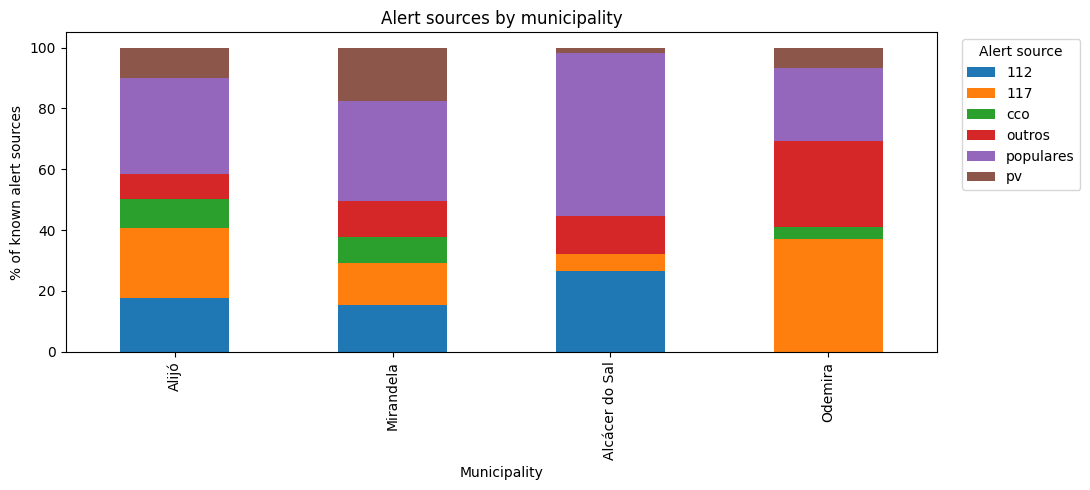

In [9]:

# --------------------------------------------------
# RQ3 — MUNICIPALITY AND ALERT SOURCE
# --------------------------------------------------

# Keep records with known alert sources
alerts = df.dropna(
    subset=['FonteAlerta_key']
).copy()

print('Records with known alert source:', len(alerts))
print('Records excluded:', len(df) - len(alerts))

# --------------------------------------------------
# GROUP RARE ALERT-SOURCE CATEGORY
# --------------------------------------------------

alerts['FonteAlertaAgrupada'] = (
    alerts['FonteAlerta_key'].replace({
        'sapadores': 'outros'
    })
)

print('Alert-source categories:')
display(
    alerts['FonteAlertaAgrupada']
    .value_counts()
    .to_frame('Occurrences')
)

# --------------------------------------------------
# CONTINGENCY TABLE
# --------------------------------------------------

alert_table = pd.crosstab(
    alerts['Municipio'],
    alerts['FonteAlertaAgrupada']
).reindex(
    MUNICIPALITIES,
    fill_value=0
)

print('Alert-source counts:')
display(alert_table)

# --------------------------------------------------
# CHI-SQUARE TEST
# --------------------------------------------------

chi_square = stats.chi2_contingency(
    alert_table,
    correction=False
)

expected = pd.DataFrame(
    chi_square.expected_freq,
    index=alert_table.index,
    columns=alert_table.columns
)

print('Chi-square statistic:', chi_square.statistic)
print('p-value:', chi_square.pvalue)
print('Degrees of freedom:', chi_square.dof)
print('Smallest expected count:', expected.min().min())

small_expected = int(
    (expected < 5).to_numpy().sum()
)

print(
    'Cells with expected count < 5:',
    small_expected,
    'out of',
    expected.size
)

print(
    'Reject H0 at 5%:',
    chi_square.pvalue < ALPHA
)

if small_expected > 0:
    print(
        'WARNING: Some expected counts are below 5. '
        'Review the chi-square approximation.'
    )

# --------------------------------------------------
# CRAMER'S V
# --------------------------------------------------

n = alert_table.to_numpy().sum()
r, c = alert_table.shape

cramers_v = np.sqrt(
    chi_square.statistic
    / (n * min(r - 1, c - 1))
)

print("Cramer's V:", cramers_v)

# --------------------------------------------------
# PERCENTAGES BY MUNICIPALITY
# --------------------------------------------------

alert_percentages = alert_table.div(
    alert_table.sum(axis=1),
    axis=0
) * 100

print('Alert-source percentages by municipality:')
display(alert_percentages.round(2))

# --------------------------------------------------
# STACKED BAR CHART
# --------------------------------------------------

ax = alert_percentages.plot.bar(
    stacked=True,
    figsize=(11, 5)
)

ax.set_title('Alert sources by municipality')
ax.set_xlabel('Municipality')
ax.set_ylabel('% of known alert sources')

ax.legend(
    title='Alert source',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()
plt.show()


### Results and interpretation — alert-source categories

All **884 incidents** have a recorded alert source. After the category grouping, the chi-square test gives **χ²(15) = 216.99**, **p ≈ 7.34 × 10⁻³⁸**, and **Cramér's V = 0.286**. No expected cell frequency is below 5 (**minimum ≈ 9.47**), so the usual chi-square approximation is not undermined by sparse expected counts in this table.

We **reject the null hypothesis of independence**: the composition of recorded alert sources is associated with municipality. Cramér's V suggests an association that is not merely negligible, although its substantive meaning depends on the specific categories and recording practices.

For example, `Populares` accounts for **53.55%** of known alert sources in **Alcácer do Sal**, compared with **24.07% in Odemira**, **31.55% in Alijó** and **32.89% in Mirandela**. In Odemira, the `117` category represents **36.93%** of records, whereas the corresponding share is only **5.81%** in Alcácer do Sal. These examples illustrate why the overall category distributions differ.

**Limitation:** `FonteAlerta` refers to how the fire alert was **recorded**, not to the proven ignition cause or to all individuals who may have witnessed the incident. Differences in local procedures and coding may contribute to the observed association.

## 9. Research question 4 — Did the share of alerts recorded as `Populares` change?

We define a `PublicAlert` indicator equal to 1 when the recorded alert source is `Populares`. A two-proportion Z-test compares the proportion of these alerts between the two periods. The difference and 95% confidence interval are reported as **post minus pre**.

In [10]:

# --------------------------------------------------
# RQ4 — PUBLIC ALERT PROPORTIONS
# --------------------------------------------------

# Use the dataset with known alert sources
# created in Block 7

alerts['PublicAlert'] = (
    alerts['FonteAlerta_key'].eq(PUBLIC_KEY)
)

# --------------------------------------------------
# PUBLIC ALERT COUNTS AND PROPORTIONS
# --------------------------------------------------

public = (
    alerts.groupby('Periodo')['PublicAlert']
    .agg(['sum', 'count'])
    .reindex([PRE, POST])
)

public['non_public'] = (
    public['count'] - public['sum']
)

public['proportion'] = (
    public['sum'] / public['count']
)

print('Public-alert definition: Populares')
display(public)

# --------------------------------------------------
# PRE AND POST PROPORTIONS
# --------------------------------------------------

pre = public.loc[PRE]
post = public.loc[POST]

difference = (
    post['proportion'] - pre['proportion']
)

# --------------------------------------------------
# 95% CONFIDENCE INTERVAL
# --------------------------------------------------

# Unpooled standard error
se = np.sqrt(
    pre['proportion']
    * (1 - pre['proportion'])
    / pre['count']

    +

    post['proportion']
    * (1 - post['proportion'])
    / post['count']
)

z_critical = stats.norm.ppf(
    1 - ALPHA / 2
)

ci = (
    difference - z_critical * se,
    difference + z_critical * se
)

# --------------------------------------------------
# TWO-PROPORTION Z-TEST
# --------------------------------------------------

# Pooled proportion under H0
pooled = (
    pre['sum'] + post['sum']
) / (
    pre['count'] + post['count']
)

# Pooled standard error
pooled_se = np.sqrt(
    pooled * (1 - pooled)
    * (
        1 / pre['count']
        +
        1 / post['count']
    )
)

# Z statistic
z = difference / pooled_se

# Two-sided p-value
p_value = 2 * stats.norm.sf(abs(z))

# --------------------------------------------------
# RESULTS
# --------------------------------------------------

print('Post-minus-pre difference:', difference)
print('95% confidence interval:', ci)
print('Two-proportion Z statistic:', z)
print('Two-sided p-value:', p_value)
print('Reject H0 at 5%:', p_value < ALPHA)

# Check sample counts
print(
    'PRE public/non-public:',
    int(pre['sum']),
    int(pre['non_public'])
)

print(
    'POST public/non-public:',
    int(post['sum']),
    int(post['non_public'])
)

# --------------------------------------------------
# ADDITIONAL COMPARISON BY MUNICIPALITY
# --------------------------------------------------

municipality_public = (
    alerts.groupby(
        ['Municipio', 'Periodo']
    )['PublicAlert']
    .agg(['sum', 'count'])
)

municipality_public['proportion'] = (
    municipality_public['sum']
    / municipality_public['count']
)

print('Public-alert proportions by municipality:')
display(municipality_public.round(3))


Public-alert definition: Populares


,sum,count,non_public,proportion
Periodo,,,,
2014-2016,236,515,279,0.458252
2018-2020,63,369,306,0.170732


Post-minus-pre difference: -0.2875207198673928
95% confidence interval: (np.float64(-0.3451898022594544), np.float64(-0.22985163747533124))
Two-proportion Z statistic: -8.910427687050973
Two-sided p-value: 5.083607755460142e-19
Reject H0 at 5%: True
PRE public/non-public: 236 279
POST public/non-public: 63 306


Public-alert proportions by municipality:


sum  count  proportion
Municipio      Periodo                          
Alcácer do Sal 2014-2016   60     85       0.706
               2018-2020   23     70       0.329
Alijó          2014-2016   49    116       0.422
               2018-2020   10     71       0.141
Mirandela      2014-2016   93    186       0.500
               2018-2020    6    115       0.052
Odemira        2014-2016   34    128       0.266
               2018-2020   24    113       0.212

### Results and interpretation — public-alert share

In 2014–2016, **236 of 515 incidents** (approximately **45.83%**) have `Populares` as their recorded alert source. In 2018–2020, the figure is **63 of 369** (approximately **17.07%**). The observed difference is **−0.2875**, or **−28.75 percentage points**, with a **95% confidence interval [−34.52, −22.99] percentage points**. The two-sided Z-test produces **z = −8.91** and **p ≈ 5.08 × 10⁻¹⁹**.

The null hypothesis of equal proportions is **rejected at 5%**. There is strong statistical evidence of an association between the period and whether an alert was recorded under `Populares`, with a lower proportion in the later period.

The decline appears in **all four municipalities** in the descriptive table: Alijó (**42.2% to 14.1%**), Mirandela (**50.0% to 5.2%**), Alcácer do Sal (**70.6% to 32.9%**) and Odemira (**26.6% to 21.2%**). The size of the change varies considerably across municipalities, so the aggregate result does not describe every locality equally well.

**Crucially, this is the percentage of incidents classified under `Populares`**, not the population's propensity to report fires. The change may reflect communication systems, local practices, category definitions or changes in incident composition, and is **not proof of a behavioural change caused by 2017**.

## 10. Research question 5 — Do burned-area distributions differ across municipalities?

The outcome `AreaTotal_ha` is analysed **in the original hectare scale**. Because its distribution is markedly right-skewed, the original report uses the **Kruskal–Wallis rank test** rather than classical equal-variance ANOVA. This tests differences in rank distributions; it **does not directly test equality of arithmetic mean burned areas**.

Burned-area summary by municipality:


,count,mean,median,std
Municipio,,,,
Alijó,187,17.40,0.18,98.17
Mirandela,301,3.91,0.12,26.01
Alcácer do Sal,155,1.24,0.08,3.90
Odemira,241,5.54,0.18,47.10


Kruskal-Wallis test for burned area: KruskalResult(statistic=np.float64(4.44065831626262), pvalue=np.float64(0.2176448998265229))
Reject H0 at 5%: False


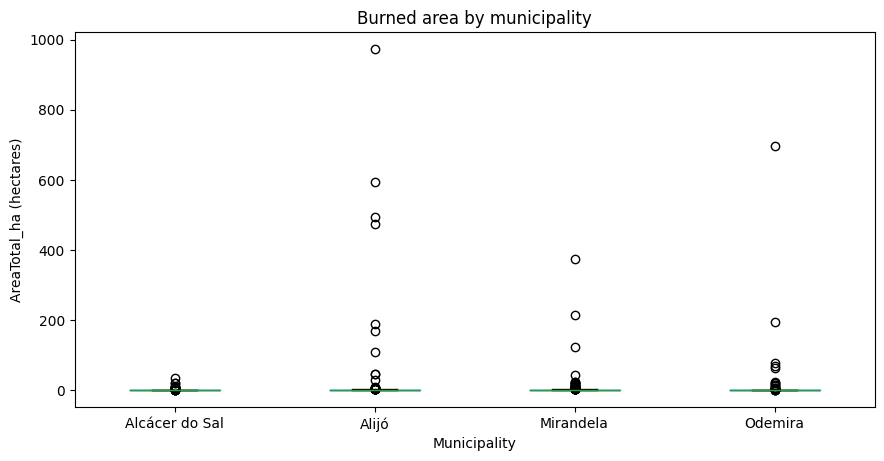

In [11]:

# --------------------------------------------------
# BURNED AREA BY MUNICIPALITY
# --------------------------------------------------

# Descriptive statistics
area_summary = (
    df.groupby('Municipio')['AreaTotal_ha']
    .agg(['count', 'mean', 'median', 'std'])
    .reindex(MUNICIPALITIES)
    .round(2)
)

# Create groups for Kruskal-Wallis
area_groups = [
    df.loc[
        df['Municipio'] == municipality,
        'AreaTotal_ha'
    ].dropna().to_numpy()
    for municipality in MUNICIPALITIES
]

# --------------------------------------------------
# KRUSKAL-WALLIS TEST
# --------------------------------------------------

area_test = stats.kruskal(*area_groups)

print('Burned-area summary by municipality:')
display(area_summary)

print(
    'Kruskal-Wallis test for burned area:',
    area_test
)

print(
    'Reject H0 at 5%:',
    area_test.pvalue < ALPHA
)

# --------------------------------------------------
# BOXPLOT
# --------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

df.boxplot(
    column='AreaTotal_ha',
    by='Municipio',
    ax=ax,
    grid=False
)

ax.set_title('Burned area by municipality')
ax.set_xlabel('Municipality')
ax.set_ylabel('AreaTotal_ha (hectares)')

fig.suptitle('')
plt.show()


### Results and interpretation — burned area

There are substantial descriptive differences between municipality means: **17.40 ha (Alijó)**, **5.54 ha (Odemira)**, **3.91 ha (Mirandela)** and **1.24 ha (Alcácer do Sal)**. However, the corresponding medians are only **0.18 ha, 0.18 ha, 0.12 ha and 0.08 ha**, respectively. The very large standard deviations — particularly **98.17 ha in Alijó** — demonstrate why arithmetic means are highly sensitive to a small number of large incidents.

The Kruskal–Wallis test gives **H = 4.44**, **p = 0.2176**. At the 5% significance level, we **fail to reject** its null hypothesis. The available data **do not provide sufficient statistical evidence of a difference in burned-area rank distributions** among these municipalities.

This is **not evidence that the populations are identical**, nor does it prove equal means. The result does not cancel the observed descriptive differences; it shows that the **rank-based test did not find them statistically compelling at the chosen level**, given the distributions and sample sizes. Automatic removal of large fires would be inappropriate without evidence that they are recording errors.

## 11. Research question 6 — Is recorded cause classification associated with municipality?

The analysis uses the recorded `GrupoCausa` variable. The eight most frequent cause groups remain separate and the less frequent groups are combined as `Outros`. A chi-square test compares the relative frequencies of the nine resulting categories among municipalities.

In [12]:

# --------------------------------------------------
# FIRE CAUSE GROUPS BY MUNICIPALITY
# --------------------------------------------------

# Keep only records with known cause groups
causes_df = df.dropna(
    subset=['GrupoCausa']
).copy()

print('Records with known cause:', len(causes_df))
print('Excluded missing causes:', len(df) - len(causes_df))

# --------------------------------------------------
# TOP 8 MOST FREQUENT CAUSE GROUPS
# --------------------------------------------------

top_causes = (
    causes_df['GrupoCausa']
    .value_counts()
    .head(8)
    .index
)

# Group less frequent causes into "Outros"
causes_df['GrupoCausaAgrupado'] = (
    causes_df['GrupoCausa'].where(
        causes_df['GrupoCausa'].isin(top_causes),
        'Outros'
    )
)

print('Most frequent cause groups:')

display(
    causes_df['GrupoCausaAgrupado']
    .value_counts()
    .to_frame('Ocorrencias')
)

# --------------------------------------------------
# CONTINGENCY TABLE
# --------------------------------------------------

cause_table = pd.crosstab(
    causes_df['Municipio'],
    causes_df['GrupoCausaAgrupado']
).reindex(
    MUNICIPALITIES,
    fill_value=0
)

print('Cause groups by municipality:')
display(cause_table)

# --------------------------------------------------
# CHI-SQUARE TEST
# --------------------------------------------------

cause_test = stats.chi2_contingency(
    cause_table,
    correction=False
)

print('Chi-square statistic:', cause_test.statistic)
print('p-value:', cause_test.pvalue)
print('Degrees of freedom:', cause_test.dof)
print(
    'Smallest expected count:',
    cause_test.expected_freq.min()
)

small_expected_causes = int(
    (cause_test.expected_freq < 5).sum()
)

print(
    'Cells with expected count < 5:',
    small_expected_causes,
    'out of',
    cause_test.expected_freq.size
)

print(
    'Reject H0 at 5%:',
    cause_test.pvalue < ALPHA
)

if small_expected_causes > 0:
    print(
        'WARNING: Some expected counts are below 5. '
        'Review the cause categories.'
    )

# --------------------------------------------------
# PERCENTAGES BY MUNICIPALITY
# --------------------------------------------------

cause_percentages = cause_table.div(
    cause_table.sum(axis=1),
    axis=0
) * 100

print('Cause percentages by municipality:')
display(cause_percentages.round(2))


Records with known cause: 847
Excluded missing causes: 37
Most frequent cause groups:


,Ocorrencias
GrupoCausaAgrupado,
Indeterminadas,259
Incendiarismo - Imputáveis,127
Queimadas de sobrantes florestais ou agrícolas,105
Queimas amontoados de sobrantes florestais ou agrícolas,94
Outros,81
Acidentais - Transportes e Comunicações,64
Acidentais - Maquinaria,58
Reacendimentos,30
Queimadas para gestão de pasto para gado,29


Cause groups by municipality:


GrupoCausaAgrupado,Acidentais - Maquinaria,Acidentais - Transportes e Comunicações,Incendiarismo - Imputáveis,Indeterminadas,Outros,Queimadas de sobrantes florestais ou agrícolas,Queimadas para gestão de pasto para gado,Queimas amontoados de sobrantes florestais ou agrícolas,Reacendimentos
Municipio,,,,,,,,,
Alijó,1,1,61,24,8,20,19,19,4
Mirandela,12,6,52,82,39,48,9,26,24
Alcácer do Sal,19,17,2,84,9,19,0,1,2
Odemira,26,40,12,69,25,18,1,48,0


Chi-square statistic: 340.6076382481474
p-value: 1.0212124909623383e-57
Degrees of freedom: 24
Smallest expected count: 5.238488783943329
Cells with expected count < 5: 0 out of 36
Reject H0 at 5%: True
Cause percentages by municipality:


GrupoCausaAgrupado,Acidentais - Maquinaria,Acidentais - Transportes e Comunicações,Incendiarismo - Imputáveis,Indeterminadas,Outros,Queimadas de sobrantes florestais ou agrícolas,Queimadas para gestão de pasto para gado,Queimas amontoados de sobrantes florestais ou agrícolas,Reacendimentos
Municipio,,,,,,,,,
Alijó,0.64,0.64,38.85,15.29,5.10,12.74,12.10,12.10,2.55
Mirandela,4.03,2.01,17.45,27.52,13.09,16.11,3.02,8.72,8.05
Alcácer do Sal,12.42,11.11,1.31,54.90,5.88,12.42,0.00,0.65,1.31
Odemira,10.88,16.74,5.02,28.87,10.46,7.53,0.42,20.08,0.00


### Results and interpretation — cause-group classification

Cause groups are available for **847 of the 884 selected incidents**; **37 records (4.2%)** have no classification and are excluded from this test. The chi-square result is **χ²(24) = 340.61**, **p ≈ 1.02 × 10⁻⁵⁷**, with **no expected count below 5** (minimum ≈ **5.24**).

We **reject the null hypothesis of independence**: the distribution of **recorded cause classifications** differs significantly between the four municipalities.

The category mix illustrates the association. In **Alijó**, `Incendiarismo - Imputáveis` accounts for approximately **38.85%** of classified records; in **Alcácer do Sal**, `Indeterminadas` accounts for approximately **54.90%**; and in **Odemira**, `Queimas amontoados de sobrantes florestais ou agrícolas` accounts for approximately **20.08%**. These are percentages **within each municipality's records with a known cause group**, not percentages of the entire regional population or proven rates of causal mechanisms.

**Important limitation:** The share of `Indeterminadas` and the exclusion of missing classifications show that recording and investigation completeness may differ. The chi-square association does **not** establish that one municipality inherently causes more fires of a specific type, nor does it isolate causal effects of local characteristics.

## 12. Integrated discussion

Taken together, the analyses suggest **three main patterns** within the selected municipality-year dataset.

**First, recorded fire frequency is lower in the later period.** The total decreases from **515 to 369**, and the mean count per municipality-month falls from **3.58 to 2.56**. The Welch t-test finds a statistically significant mean difference (p = **0.0212**), but the magnitude is modest (Cohen's d ≈ **−0.27**) and the inference should be qualified because municipality-month observations may be temporally dependent.

**Second, response times and recorded alert-source composition vary by municipality.** Welch ANOVA finds differences in mean first-intervention time (p ≈ **4.59 × 10⁻¹⁴**). The post-hoc analysis detects significant contrasts in five of six pairs, with Mirandela having the shortest observed mean and Odemira the longest. Independently, the distribution of alert-source categories is associated with municipality (χ² p ≈ **7.34 × 10⁻³⁸**, Cramér's V ≈ **0.286**). The share of incidents recorded as `Populares` also falls from **45.83%** to **17.07%** between the two periods, a reduction of **28.75 percentage points** (95% CI for post − pre: **[−34.52, −22.99] pp**). These associations should not be interpreted as evidence that one factor *caused* another.

**Third, the fire-size and recorded-cause findings differ.** Descriptive arithmetic mean burned areas vary substantially but are highly affected by extreme observations. The Kruskal–Wallis test finds **no statistically significant difference in burned-area rank distributions** (p = **0.2176**). By contrast, recorded cause-group composition is strongly associated with municipality (χ² p ≈ **1.02 × 10⁻⁵⁷**), although unknown or missing causes require caution.

A statistically significant result indicates evidence against a specific null hypothesis **under the model assumptions**; it does not measure the importance of the difference by itself. Conversely, a non-significant result does not demonstrate that the groups are identical.

## 13. Limitations and implications

**Scope and representativeness.** The analysis covers **four purposively selected municipalities** and two three-year periods, not a probability sample of Portugal. The conclusions describe these records and may not generalise to other municipalities or dates. Different municipality sizes, vegetation, exposure, and recording completeness can make raw event counts difficult to compare as population rates.

**Temporal comparisons and independence.** **2017 was excluded** as a transition year, but this does not create a controlled before-and-after experiment or demonstrate a policy effect. Monthly observations are likely to be influenced by seasonality, recurring weather conditions and within-municipality dependence. The Welch t-test on municipality-month counts assumes more independence than may hold in practice, so its confidence interval and p-value should be treated with caution. Annual/month effects or models that account for temporal structure would be appropriate extensions.

**Response-time measurement.** Response intervals are derived from two recorded timestamps. Two invalid or missing values are omitted; long but plausible times are retained. Unequal group variances were detected (Levene p = **0.00160**), motivating Welch ANOVA. Response-time differences can reflect distance, access, fire severity, location and recording procedures, none of which is controlled for in this simple comparison.

**Alert and cause classification.** Alert-source and cause analyses concern **recorded categories**, whose composition can be affected by classification practices. In the cause analysis, **37 missing records** are omitted; the remaining rare causes are grouped under `Outros`. Association does not imply causation. Since multiple distinct hypotheses were explored, statistical significance should be interpreted together with the consistency and practical meaning of results.

**Burned-area skewness.** The large difference between means and medians indicates highly skewed areas and influential incidents. The Kruskal–Wallis result concerns ranks/distributions, **not** an estimated difference between arithmetic means in hectares. More informative follow-up work could report robust quantiles and examine extreme-event contributions explicitly rather than deleting genuine high-area fires.

**Recommended next analyses.** To strengthen interpretation, one could (i) account for seasonal and municipal effects in the count comparison; (ii) standardise fire frequency by a relevant exposure denominator, where available; (iii) evaluate response times with relevant access/location covariates; and (iv) investigate whether alert-source and cause-category coding changed over time. These are proposed improvements, **not analyses performed in this report**.

## 14. Final conclusions

Within the selected SGIF records for **Alijó, Mirandela, Alcácer do Sal and Odemira**, recorded fire incidents were **less frequent in 2018–2020 than in 2014–2016**, both descriptively and in the Welch comparison of mean municipality-month counts. The analysis also found **statistically significant differences in mean first-intervention times**, as well as **associations between municipality and the recorded alert-source and cause-group categories**. The percentage of incidents whose alert source was recorded as `Populares` was markedly lower in the later period.

In contrast, although arithmetic mean burned areas differed descriptively, the **Kruskal–Wallis test did not find sufficient statistical evidence of differences in burned-area rank distributions** across municipalities. This important distinction prevents treating every visible numerical difference as statistically established.

These findings identify **patterns and associations in a defined observational dataset**, rather than causal impacts of 2017 or general facts about all Portuguese rural fires. The study's main value is the combination of data preparation, descriptive exploration, appropriate comparative tests and cautious interpretation. Stronger conclusions would require attention to temporal dependence, geographic exposure, recording practices and relevant confounding variables.